Water Health Classifier Using Machine Learning

File ini untuk melakukan EDA dan melatih model hingga bisa prediksi air berdasarkan dataset dari assignment 2 untuk prediksi apakah air clear / slightly turbid / dirty

## EDA

In [1]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

LABELS = ["clear", "slightly_turbid", "dirty"]
COLORS = {"clear": "#2a9d8f", "slightly_turbid": "#e9c46a", "dirty": "#a0522d"}

raw = pd.read_csv("data/iot_project_dataset_2026-11-04.csv")
raw["timestamp_wib"] = pd.to_datetime(raw["timestamp_wib"])
print("Jumlah baris:", len(raw), "| kolom:", raw.shape[1])
raw.head()

Jumlah baris: 1022 | kolom: 7


,timestamp_wib,t_tank,tds,tds_v,turb,turb_v,label
0,2026-11-03 19:44:46,21.44,277.5,0.696,9.1,1.700,clear
1,2026-11-03 19:44:49,21.44,277.5,0.696,9.3,1.699,clear
2,2026-11-03 19:44:52,21.44,277.5,0.696,9.1,1.700,clear
3,2026-11-03 19:44:55,21.44,277.4,0.696,9.5,1.698,clear
4,2026-11-03 19:44:59,21.44,277.5,0.696,9.5,1.698,clear


Dataset Descirption

| Kolom | Isi |
|---|---|
| timestamp_wib | waktu pembacaan (WIB) |
| t_tank | suhu air dari DS18B20 (Celcius) |
| tds, tds_v | TDS dalam ppm dan raw voltage sensor |
| turb, turb_v | indeks kekeruhan 0-100 dan raw voltage sensor (makin tinggi V = makin jernih) |
| label | kondisi air yang diset di dashboard (target) |

In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1022 entries, 0 to 1021
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp_wib  1022 non-null   datetime64[ns]
 1   t_tank         1022 non-null   float64       
 2   tds            1022 non-null   float64       
 3   tds_v          1022 non-null   float64       
 4   turb           1022 non-null   float64       
 5   turb_v         1022 non-null   float64       
 6   label          1022 non-null   object        
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 56.0+ KB


In [3]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp_wib,1022,2026-11-03 20:10:30.792563712,2026-11-03 19:44:46,2026-11-03 19:57:36.750000128,2026-11-03 20:10:29.500000,2026-11-03 20:23:24.249999872,2026-11-03 20:36:20,NaN
t_tank,1022.0,22.185,21.38,21.56,22.5,22.56,22.63,0.476
tds,1022.0,546.547,260.3,277.0,357.8,969.1,981.6,314.167
tds_v,1022.0,1.233,0.652,0.695,0.927,2.013,2.027,0.584
turb,1022.0,35.161,0.0,8.5,36.8,59.6,83.1,25.094
turb_v,1022.0,1.557,1.293,1.422,1.547,1.703,1.764,0.138


In [4]:
print("Missing value per kolom:")
print(raw.isna().sum())
print()
print("Jumlah baris per label:")
print(raw["label"].value_counts(dropna=False))

Missing value per kolom:
timestamp_wib    0
t_tank           0
tds              0
tds_v            0
turb             0
turb_v           0
label            0
dtype: int64

Jumlah baris per label:
label
dirty              359
clear              334
slightly_turbid    329
Name: count, dtype: int64


In [5]:
raw.groupby("label")["timestamp_wib"].agg(["min", "max", "count"])

,min,max,count
label,,,
clear,2026-11-03 19:44:46,2026-11-03 20:01:31,334
dirty,2026-11-03 20:18:13,2026-11-03 20:36:20,359
slightly_turbid,2026-11-03 20:01:34,2026-11-03 20:18:10,329


In [6]:
df = raw.dropna(subset=["label", "t_tank", "tds", "turb_v"])
df = df.sort_values("timestamp_wib").reset_index(drop=True)
df["label"] = pd.Categorical(df["label"], categories=LABELS, ordered=True)

print("Sebelum cleaning:", len(raw))
print("Sesudah cleaning:", len(df))
print()
print(df["label"].value_counts().sort_index())

Sebelum cleaning: 1022
Sesudah cleaning: 1022

label
clear              334
slightly_turbid    329
dirty              359
Name: count, dtype: int64


Bisa dilihat bahwa tidak ada missing value dan datanya aman

### Statistik per label

In [7]:
SENSORS = ["tds", "turb_v", "t_tank"]
df.groupby("label", observed=True)[SENSORS].agg(["mean", "std", "min", "max"]).T

label          clear  slightly_turbid    dirty
tds    mean  276.287          357.974  970.801
       std     1.177            2.122   12.971
       min   260.300          346.100  902.400
       max   277.900          365.500  981.600
turb_v mean    1.721            1.549    1.411
       std     0.019            0.064    0.060
       min     1.690            1.448    1.293
       max     1.764            1.666    1.589
t_tank mean   21.521           22.508   22.507
       std     0.056            0.188    0.032
       min    21.380           21.560   22.440
       max    21.630           22.630   22.560

### Jumlah data per label

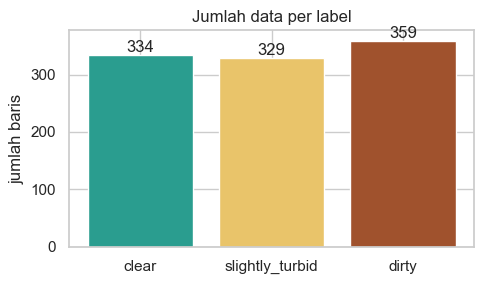

In [8]:
counts = df["label"].value_counts().reindex(LABELS)

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color=[COLORS[l] for l in LABELS])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, v, ha="center")
ax.set_ylabel("jumlah baris")
ax.set_title("Jumlah data per label")
fig.tight_layout()
fig.savefig("results/class_balance.png", dpi=150)
plt.show()

Jumlah data per label hampir sama / balance, jadi aman untuk digunakan langsung

### Nilai sensor overtime

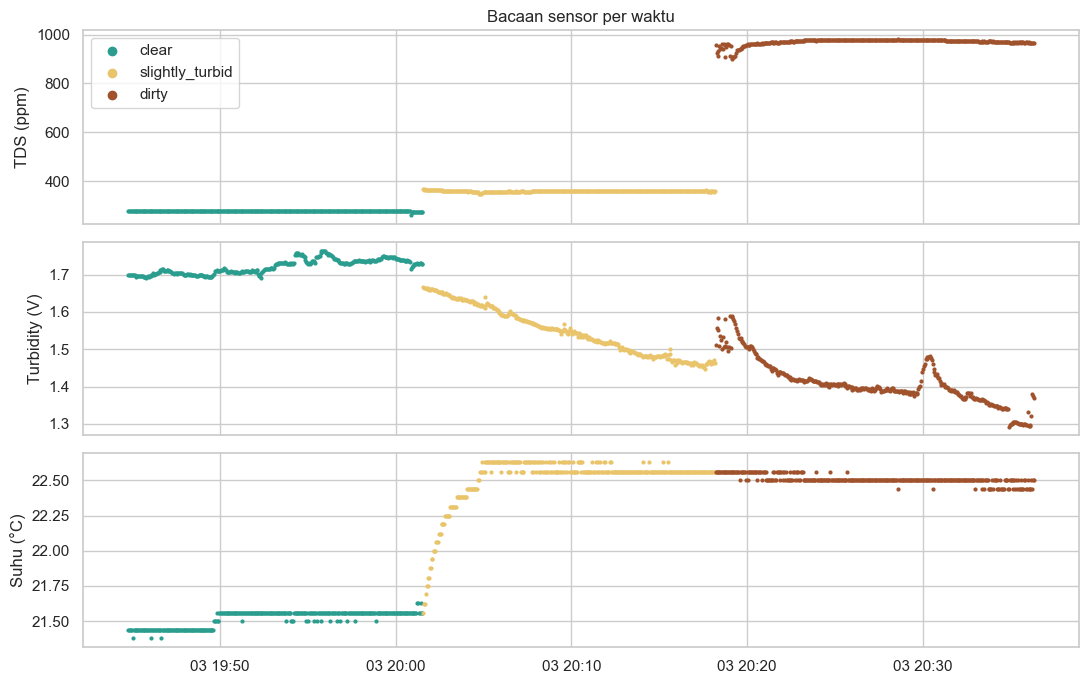

In [9]:
names = {"tds": "TDS (ppm)", "turb_v": "Turbidity (V)", "t_tank": "Suhu (°C)"}

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, col in zip(axes, SENSORS):
    for label in LABELS:
        part = df[df["label"] == label]
        ax.scatter(part["timestamp_wib"], part[col], s=4, color=COLORS[label], label=label)
    ax.set_ylabel(names[col])
axes[0].legend(loc="upper left", markerscale=3)
axes[0].set_title("Bacaan sensor per waktu")
fig.tight_layout()
fig.savefig("results/time_series.png", dpi=150)
plt.show()

Dari grafik itu dapat dilihat nilai DTS itu stabil per 1 session / label tpi angkanya beda jauh antar session di sekitar 276/358/970 ppm.
Lalu, Voltage turbidity bisa diliat menurun ketika air jadi kotor, tapi nilainya masih naik turun di 1 session yg sama.
Terakhir, suhu kalau diliat dari grafik itu cuma berbeda di sekitar 1 derajat ceclius antar sesi , tapi ini karna perubahan suhu ruang bukan airnya sendiri jadi suhu tidak memengaruh kualitas air 

### Distribusi nilai per label

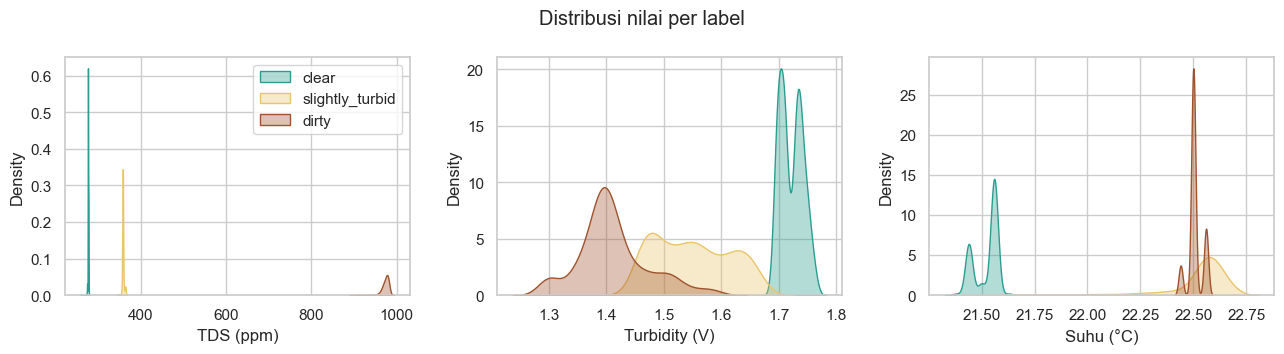

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, SENSORS):
    for label in LABELS:
        sns.kdeplot(df[df["label"] == label][col], ax=ax, fill=True, alpha=0.35,
                    color=COLORS[label], label=label, warn_singular=False)
    ax.set_xlabel(names[col])
axes[0].legend()
fig.suptitle("Distribusi nilai per label")
fig.tight_layout()
fig.savefig("results/distributions.png", dpi=150)
plt.show()

Dari grafik distribusi, nilai TDS tiap label tidak overlap, jadi sbrnnya cuma apake TDS udh bisa pisahin 3 labbel. Sedangkan Turbidity clean paling tinggi dan teripsah tpi 2 label lainnya masih saling overlap. Terakhir suhu clear cuma beda 1 derajt sehingga untuk suhu ini tidak terlalu dipakai.

### 4.5 TDS vs turbidity

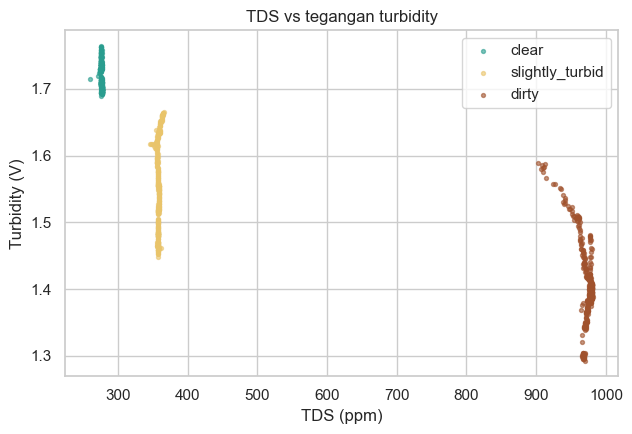

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label in LABELS:
    part = df[df["label"] == label]
    ax.scatter(part["tds"], part["turb_v"], s=8, alpha=0.6, color=COLORS[label], label=label)
ax.set_xlabel("TDS (ppm)")
ax.set_ylabel("Turbidity (V)")
ax.set_title("TDS vs tegangan turbidity")
ax.legend()
fig.tight_layout()
fig.savefig("results/scatter_tds_turb.png", dpi=150)
plt.show()

Dari scatter plot, tiap kelas data membentuk kelompok yang trpisah dengas jelas di sepanjang sumbu TDS. Tapi untuk turbidity, dsitribusi slightly tubid dan dirty masih ada overlap dimana nunjukkin iftur ini tidak cukup kalau sendiri. Jadi disini, saya menggunaakan kombinasi dari TDS dan turbitdity voltage untuk bisa pecahin 3 label dengan lebih baik dan digunakan di model

### Feature Selection

Kita uji modelnya menggunakan bebebrapa kombinasi ada 4:
1. tds dan turb_v
2. tds aja 
3. turb_v aja
4. ketiga sensor (tds, turb_v dan t_tank)

In [12]:
FEATURE_SETS = {
    "tds + turb_v": ["tds", "turb_v"],
    "tds": ["tds"],
    "turb_v": ["turb_v"],
    "tds + turb_v + t_tank": ["tds", "turb_v", "t_tank"],
}
FEATURES = FEATURE_SETS["tds + turb_v"]

### Split train/test

Kita split train testnya dengan cara mengambil 80% dari recording awal buat train dan 20% akhir buat test.
Lalu, untuk cross validation di data train, tiap label dipotong jdi  blok beruutan terus pake GroupKFlod untuk mmenjaga biar satu blok selalu ada di fold yg sama

In [13]:
TEST_SIZE = 0.2
N_BLOCKS = 4

train_list, test_list = [], []
for label, group in df.groupby("label", observed=True):
    cut = int(len(group) * (1 - TEST_SIZE))
    part_train = group[:cut].copy()
    part_train["block"] = np.arange(len(part_train)) * N_BLOCKS // len(part_train)
    train_list.append(part_train)
    test_list.append(group[cut:])

train = pd.concat(train_list).reset_index(drop=True)
test = pd.concat(test_list).reset_index(drop=True)

print(pd.DataFrame({"train": train["label"].value_counts(), "test": test["label"].value_counts()}).reindex(LABELS))
print("\nTotal train:", len(train), "| test:", len(test))

                 train  test
label                       
clear              267    67
slightly_turbid    263    66
dirty              287    72

Total train: 817 | test: 205


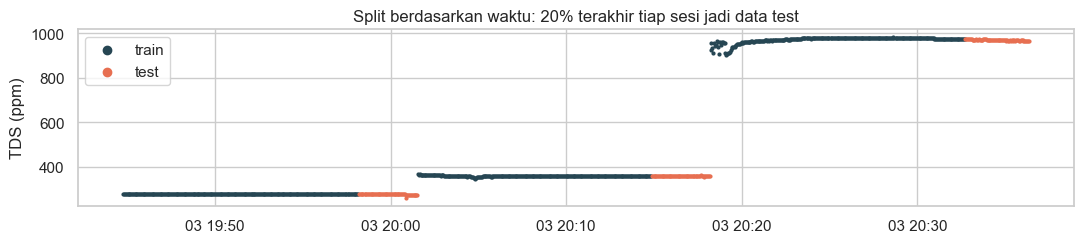

In [14]:
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.scatter(train["timestamp_wib"], train["tds"], s=4, color="#264653", label="train")
ax.scatter(test["timestamp_wib"], test["tds"], s=4, color="#e76f51", label="test")
ax.set_ylabel("TDS (ppm)")
ax.set_title("Split berdasarkan waktu: 20% terakhir tiap sesi jadi data test")
ax.legend(markerscale=3)
fig.tight_layout()
fig.savefig("results/split.png", dpi=150)
plt.show()

## Training dan perbandingan model

Ini model yang kita coba untuk milih yang terbaik

| Model | Config | Kenapa dicoba |
|---|---|---|
| Decision Tree | max_depth 3 | aturan if-else simpel dan gampang dijalanin di ESP32 |
| Random Forest | 100 tree, max_depth 5 | pakai banyak tree, jadi hasilnya lebih stabil daripada 1 tree |
| Gradient Boosting | 100 tree, max_depth 2 | model yang kuat untuk data tabel berisi angka |
| k-Nearest Neighbours | k = 5, standard scaling | ambil keputusan dari 5 bacaan lama yang paling mirip |
| Logistic Regression | standard scaling | baseline, titik awal buat dibandingin sama model lain |
| SVM | RBF kernel, standard scaling | batas keputusan non-linear |
| Naive Bayes | Gaussian | baseline paling kecil |

kita kasih StandardScaler ke k-NN, Logistic Regression, dan SVM karna mereka sensitif sama data scale

In [15]:
def make_models():
    return {
        "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=42),
        "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
        "Naive Bayes": GaussianNB(),
    }

cv = GroupKFold(n_splits=N_BLOCKS)

### Coba semua model pakai feature sensor utama (tds dan turb_v)

In [16]:
def evaluate(features):
    rows = []
    fitted = {}
    for name, model in make_models().items():
        cv_f1 = cross_val_score(model, train[features], train["label"], groups=train["block"],
                                cv=cv, scoring="f1_macro").mean()
        model.fit(train[features], train["label"])
        pred = model.predict(test[features])
        rows.append({
            "model": name,
            "cv_macro_f1": cv_f1,
            "test_accuracy": accuracy_score(test["label"], pred),
            "test_macro_f1": f1_score(test["label"], pred, average="macro"),
        })
        fitted[name] = model
    table = pd.DataFrame(rows).sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
    return table, fitted

results, fitted = evaluate(FEATURES)
results.to_csv("results/model_comparison.csv", index=False)
results

,model,cv_macro_f1,test_accuracy,test_macro_f1
0,Decision Tree,0.999,1.0,1.0
1,Random Forest,1.000,1.0,1.0
2,Gradient Boosting,0.999,1.0,1.0
3,k-NN (k=5),1.000,1.0,1.0
4,Logistic Regression,0.960,1.0,1.0
5,SVM (RBF),0.999,1.0,1.0
6,Naive Bayes,1.000,1.0,1.0


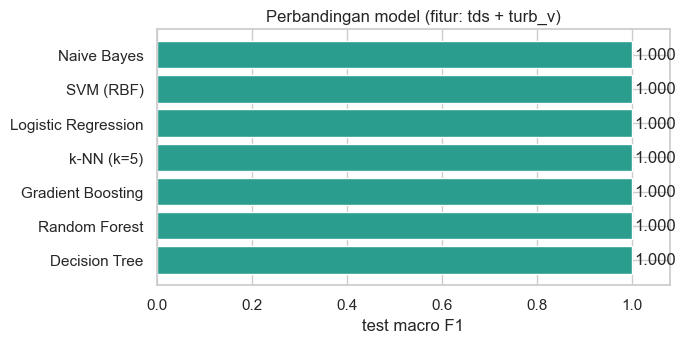

In [17]:
order = results.sort_values("test_macro_f1")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(order["model"], order["test_macro_f1"], color="#2a9d8f")
for y, v in enumerate(order["test_macro_f1"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.08)
ax.set_xlabel("test macro F1")
ax.set_title("Perbandingan model (fitur: tds + turb_v)")
fig.tight_layout()
fig.savefig("results/model_comparison.png", dpi=150)
plt.show()

### Perbandingan Kombinasi Feature yg udh dipilih di awal 

Semua model ditrain ulang pakai tiap kombinasi fitur, buat ngecek apakah fitur `tds + turb_v` yang dipilih di bagian 5 sudah tepat.

In [18]:
feature_table = pd.DataFrame()
for set_name, features in FEATURE_SETS.items():
    table, _ = evaluate(features)
    feature_table[set_name] = table.set_index("model")["test_macro_f1"]

feature_table.to_csv("results/feature_sets.csv")
feature_table.style.format("{:.3f}").background_gradient(cmap="Greens", vmin=0.3, vmax=1.0)

,tds + turb_v,tds,turb_v,tds + turb_v + t_tank
model,,,,
Decision Tree,1.000,1.000,0.695,1.000
Random Forest,1.000,1.000,0.695,1.000
Gradient Boosting,1.000,1.000,0.695,1.000
k-NN (k=5),1.000,1.000,0.695,1.000
Logistic Regression,1.000,1.000,0.573,1.000
SVM (RBF),1.000,1.000,0.695,1.000
Naive Bayes,1.000,1.000,0.573,1.000


Berdassarkan hasil itu, pakai tds aja semua model udh dapat accuracy 100 krn tds yg paling bantu masihan 3 ttable itu, sedangkan turbidity itu skorya di 0.573 - 0.695 karna label slightly turbid dan dirty masih overlap. Kalau namabhain suhu skornya ga ngaruh, makanya tidak dipakai.
Jadi, kesimpulannya kita pake tds dan turb_v dimaa tds buat misahin label dan turbidity ttp diapaki untuk nguruku kekeruhan air


## Evaluasi

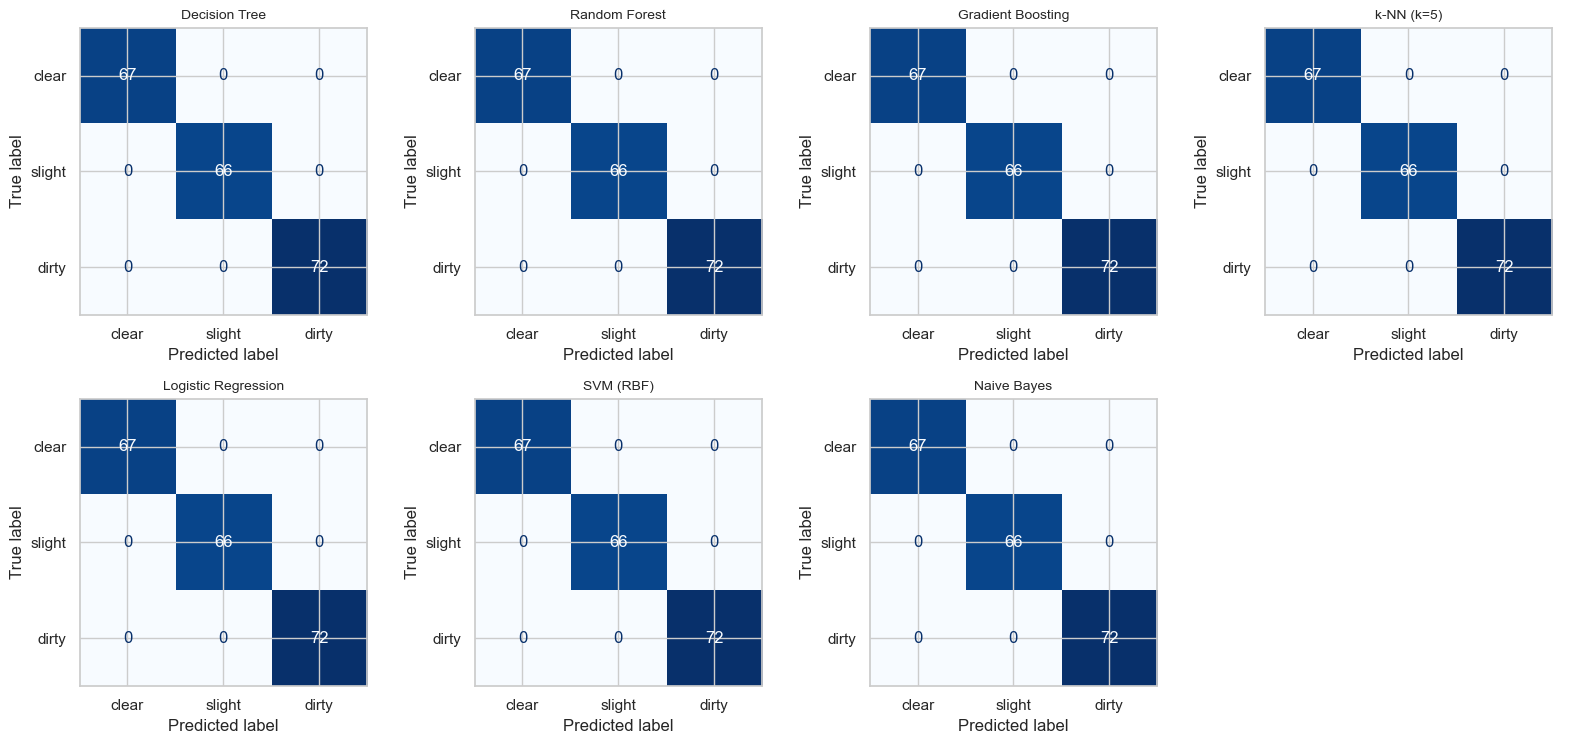

In [19]:
model_names = list(results["model"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7.6))
for ax, name in zip(axes.flat, model_names):
    pred = fitted[name].predict(test[FEATURES])
    cm = confusion_matrix(test["label"], pred, labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=["clear", "slight", "dirty"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
axes.flat[-1].axis("off")  # 7 model, kotak ke-8 dikosongin
fig.tight_layout()
fig.savefig("results/confusion_matrices.png", dpi=150)
plt.show()

Semua model bisa predict semua test dengan benar.

In [20]:
for name in model_names:
    pred = fitted[name].predict(test[FEATURES])
    print("===", name, "===")
    print(classification_report(test["label"], pred, labels=LABELS, zero_division=0))

=== Decision Tree ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        67
slightly_turbid       1.00      1.00      1.00        66
          dirty       1.00      1.00      1.00        72

       accuracy                           1.00       205
      macro avg       1.00      1.00      1.00       205
   weighted avg       1.00      1.00      1.00       205

=== Random Forest ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        67
slightly_turbid       1.00      1.00      1.00        66
          dirty       1.00      1.00      1.00        72

       accuracy                           1.00       205
      macro avg       1.00      1.00      1.00       205
   weighted avg       1.00      1.00      1.00       205

=== Gradient Boosting ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        67
slightly_tu

Semua metric scorenya full di semua model

### 8.3 Batas keputusan

Gimana tiap model ngebagi area TDS / turbidity. Titik-titiknya data test.

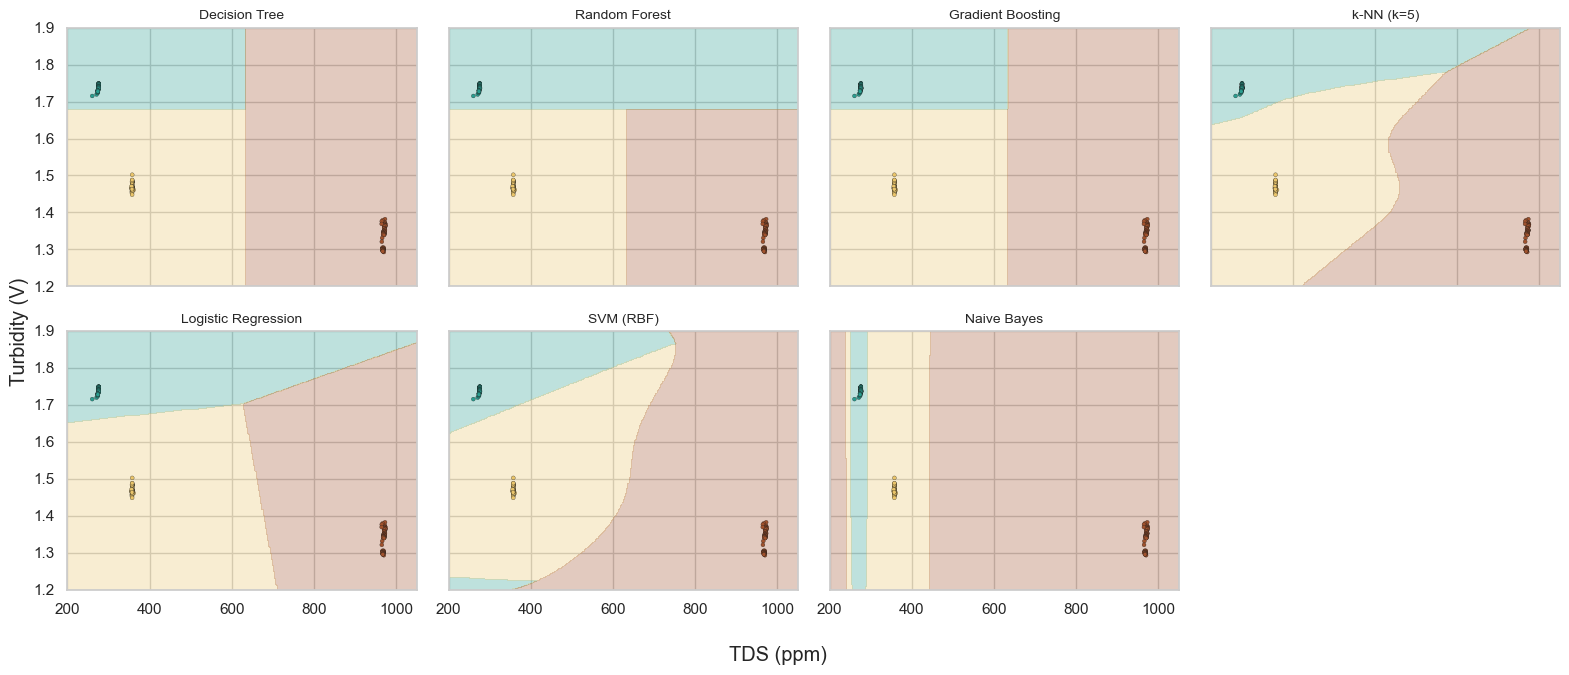

In [21]:
xx, yy = np.meshgrid(np.linspace(200, 1050, 300), np.linspace(1.2, 1.9, 300))
grid = pd.DataFrame({"tds": xx.ravel(), "turb_v": yy.ravel()})
label_to_num = {label: i for i, label in enumerate(LABELS)}
cmap = plt.matplotlib.colors.ListedColormap([COLORS[l] for l in LABELS])

fig, axes = plt.subplots(2, 4, figsize=(16, 6.8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, model_names):
    z = pd.Series(fitted[name].predict(grid)).map(label_to_num).values.reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap, alpha=0.3)
    ax.scatter(test["tds"], test["turb_v"], c=test["label"].map(label_to_num).astype(int), cmap=cmap,
               s=8, edgecolor="k", linewidth=0.2, vmin=0, vmax=2)
    ax.set_title(name, fontsize=10)
axes.flat[-1].axis("off")
fig.supxlabel("TDS (ppm)")
fig.supylabel("Turbidity (V)")
fig.tight_layout()
fig.savefig("results/decision_boundaries.png", dpi=150)
plt.show()

Kalau dilihat dari gamabr itu, semua model bisa misahin 3 kelompok titik test dengan benar walau bentuknya beda2, makanya score test semua model sama dan juga karna tdsnya memiliki level garam yg bener2 jauh 

## 9. Model mana yang muat di ESP32

ESP32 cuma punya RAM sekitar 320 KB dan nggak bisa jalanin Python, jadi modelnya harus diubah jadi kode C.
Tabel ini kira-kira berapa banyak yang harus disimpan tiap model.

In [22]:
def model_size(name, model):
    if hasattr(model, "steps"):  # pipeline, ambil model terakhirnya
        model = model[-1]
    if name == "Decision Tree":
        return model.tree_.node_count, "node", "if-else, bisa langsung diexport"
    if name == "Random Forest":
        return sum(t.tree_.node_count for t in model.estimators_), "node", "100 tree if-else, header gede"
    if name == "Gradient Boosting":
        return sum(t.tree_.node_count for t in model.estimators_.ravel()), "node", "banyak tree kecil + penjumlahan"
    if name.startswith("k-NN"):
        return model.n_samples_fit_ * len(FEATURES), "nilai", "harus simpan semua data train"
    if name == "Logistic Regression":
        return model.coef_.size + model.intercept_.size, "angka", "cuma beberapa perkalian"
    if name.startswith("SVM"):
        return model.support_vectors_.size, "nilai", "harus simpan semua support vector"
    if name == "Naive Bayes":
        return model.theta_.size + model.var_.size, "angka", "mean dan varians per kelas"

size_rows = []
for name in model_names:
    size, unit, note = model_size(name, fitted[name])
    f1 = results.set_index("model").loc[name, "test_macro_f1"]
    size_rows.append({"model": name, "ukuran": size, "satuan": unit, "di ESP32": note, "test_macro_f1": f1})
esp = pd.DataFrame(size_rows)
esp.to_csv("results/esp32_size.csv", index=False)
esp

,model,ukuran,satuan,di ESP32,test_macro_f1
0,Decision Tree,5,node,"if-else, bisa langsung diexport",1.0
1,Random Forest,690,node,"100 tree if-else, header gede",1.0
2,Gradient Boosting,1490,node,banyak tree kecil + penjumlahan,1.0
3,k-NN (k=5),1634,nilai,harus simpan semua data train,1.0
4,Logistic Regression,9,angka,cuma beberapa perkalian,1.0
5,SVM (RBF),68,nilai,harus simpan semua support vector,1.0
6,Naive Bayes,12,angka,mean dan varians per kelas,1.0



Semua model dpt skor test 1, tapi saya pilih random forest karena bentuk treenya bisa diubah jadi if else C++ pake microml gen, walau knn dan SVM bisa tapi butuh banyak data. Lalu Random Forest juga pake banyak tree jadi lebihstabil dari Decision Tree dimana tiap tree bis akasih vote yang bisa dipakai sebagai confidence. Lalu biar random forestnya lebi kecil kita coba ke tree yg lebih kecil tapi skornya ttp sama

In [23]:
# Coba Random Forest dari yang besar sampai yang kecil, pakai split dan block CV yang sama
rf_configs = [(100, 5), (50, 5), (20, 5), (10, 5), (10, 3), (10, 2), (5, 3), (3, 3)]
shrink_rows = []
for n_trees, depth in rf_configs:
    rf = RandomForestClassifier(n_estimators=n_trees, max_depth=depth, random_state=42)
    cv_f1 = cross_val_score(rf, train[FEATURES], train["label"], groups=train["block"], cv=cv, scoring="f1_macro").mean()
    rf.fit(train[FEATURES], train["label"])
    pred = rf.predict(test[FEATURES])
    shrink_rows.append({
        "n_tree": n_trees,
        "max_depth": depth,
        "node": sum(t.tree_.node_count for t in rf.estimators_),
        "cv_macro_f1": round(cv_f1, 3),
        "test_accuracy": accuracy_score(test["label"], pred),
        "test_macro_f1": f1_score(test["label"], pred, average="macro"),
        "langkah confidence": f"{100 / n_trees:.0f}%",
    })
shrink = pd.DataFrame(shrink_rows)
shrink.to_csv("results/rf_shrink.csv", index=False)
shrink

,n_tree,max_depth,node,cv_macro_f1,test_accuracy,test_macro_f1,langkah confidence
0,100,5,690,1.0,1.0,1.0,1%
1,50,5,332,1.0,1.0,1.0,2%
2,20,5,138,1.0,1.0,1.0,5%
3,10,5,66,1.0,1.0,1.0,10%
4,10,3,54,1.0,1.0,1.0,10%
5,10,2,50,1.0,1.0,1.0,10%
6,5,3,29,1.0,1.0,1.0,20%
7,3,3,15,1.0,1.0,1.0,33%


Semua ukuran tree bisa dpt skor 1, jadi yang kita pake di ESP itu 10 tree dengan max depth 3 (54 node) dimana 10 tree bisa bikin confidence naik turun per 10%, lalu depth 3 juga cukup. 54 Node ini akan dijadikan file water_model.h

### Feature importance

tds       0.67
turb_v    0.33
dtype: float64


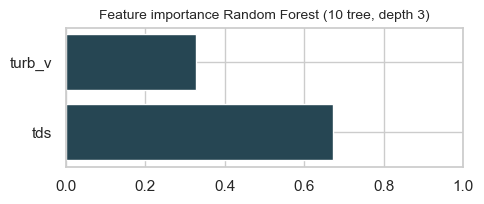

In [24]:
# Model final: setting yang dipilih (10 tree, depth 3), dilatih pakai semua data. Model ini yang dipasang di ESP32.
small_rf = RandomForestClassifier(n_estimators=10, max_depth=3, random_state=42)
small_rf.fit(df[FEATURES].values, df["label"].astype(str))
importance = pd.Series(small_rf.feature_importances_, index=FEATURES)
print(importance.round(2))

fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(FEATURES, importance.values, color="#264653")
ax.set_xlim(0, 1)
ax.set_title("Feature importance Random Forest (10 tree, depth 3)", fontsize=10)
fig.tight_layout()
fig.savefig("results/feature_importance.png", dpi=150)
plt.show()

Disini, TDS ttp lebih penting dengan feature importance 0.67 yang dipake buat misahin dirty dari 2 label lain dan turbidity dipake buat misahin clear dan slightly turbid.


Random Forest disimpan untuk nnti di psang di code esp

Setelah itu modelnya diubah jadi C++ buat firmware pakai:

```
python export_tree.py --model models/random_forest.joblib
```

In [25]:
# Ambil akurasi test setting 10 tree, depth 3 dari tabel di bagian 9
small_test = shrink.query("n_tree == 10 and max_depth == 3").iloc[0]

path = "models/random_forest.joblib"
joblib.dump({
    "model": small_rf,
    "features": FEATURES,
    "labels": LABELS,
    "name": "Random Forest (10 tree, depth 3)",
    "rows": len(df),
    "test_accuracy": float(small_test["test_accuracy"]),
    "X": df[FEATURES].values,  # buat ngecek vote ESP32 sama dengan sklearn di export_tree.py
}, path)
print("disimpan:", path)

disimpan: models/random_forest.joblib


## AI vs rule-based (Assignment 2)

Di assignment 2, airnay diganti dengan menggunakn rules health score dan sekarnag pakai rules dari AI dimana model predict dirty dengan 60% tree setuju 

Dsini kita mau bandingin bedanya gimana di tes yg sama

In [26]:
SCORE_THRESHOLD = 60
IN_A_ROW = 5
ML_MIN_CONFIDENCE = 0.6

def lin(v, good, bad):
    return 100 * (1 - np.clip((v - good) / (bad - good), 0, 1))

def health_score(row):
    t = row["t_tank"]
    temp = lin(t, 24, 20) if t < 24 else lin(t, 30, 34) if t > 30 else 100
    total = 0.5 * lin(row["tds"], 300, 700) + 0.375 * (100 - row["turb"]) + 0.125 * temp
    return round(total)

esp_model = RandomForestClassifier(n_estimators=10, max_depth=3, random_state=42)
esp_model.fit(train[FEATURES].values, train["label"])

def esp32_vote(model, X):
    votes = np.zeros((len(X), len(model.classes_)))
    for tree in model.estimators_:
        votes[np.arange(len(X)), tree.predict(X).astype(int)] += 1
    return model.classes_[votes.argmax(axis=1)], votes.max(axis=1) / len(model.estimators_)

cmp = test.sort_values("timestamp_wib").reset_index(drop=True).copy()
cmp["score"] = cmp.apply(health_score, axis=1)
cmp["ml"], cmp["ml_conf"] = esp32_vote(esp_model, cmp[FEATURES].values)

cmp["truth"] = cmp["label"] == "dirty"
cmp["rule_based"] = cmp["score"] < SCORE_THRESHOLD
cmp["ai"] = (cmp["ml"] == "dirty") & (cmp["ml_conf"] >= ML_MIN_CONFIDENCE)

cmp.groupby("label", observed=True)[["score", "ml_conf"]].describe().loc[LABELS].round(1)

score                                          ml_conf       \
                count  mean  std   min   25%   50%   75%   max   count mean   
label                                                                         
clear            67.0  91.5  0.6  90.0  91.0  92.0  92.0  92.0    67.0  1.0   
slightly_turbid  66.0  69.1  0.7  68.0  69.0  69.0  69.0  71.0    66.0  0.9   
dirty            72.0  17.1  2.0  14.0  15.0  18.0  19.0  20.0    72.0  1.0   

                                               
                 std  min  25%  50%  75%  max  
label                                          
clear            0.0  1.0  1.0  1.0  1.0  1.0  
slightly_turbid  0.0  0.9  0.9  0.9  0.9  1.0  
dirty            0.0  1.0  1.0  1.0  1.0  1.0

In [27]:
from sklearn.metrics import precision_score, recall_score

rows = []
for name, col in [("Rule-based (R1: score < 60)", "rule_based"), ("AI (R4: model bilang dirty)", "ai")]:
    rows.append({
        "sistem": name,
        "accuracy": accuracy_score(cmp["truth"], cmp[col]),
        "precision": precision_score(cmp["truth"], cmp[col], zero_division=0),
        "recall": recall_score(cmp["truth"], cmp[col], zero_division=0),
        "f1": f1_score(cmp["truth"], cmp[col], zero_division=0),
        "alarm palsu (pembacaan)": int((cmp[col] & ~cmp["truth"]).sum()),
        "kelewat (pembacaan)": int((~cmp[col] & cmp["truth"]).sum()),
    })
compare = pd.DataFrame(rows)
compare.to_csv("results/ai_vs_rule_based.csv", index=False)
compare.round(3)

,sistem,accuracy,precision,recall,f1,alarm palsu (pembacaan),kelewat (pembacaan)
0,Rule-based (R1: score < 60),1.0,1.0,1.0,1.0,0,0
1,AI (R4: model bilang dirty),1.0,1.0,1.0,1.0,0,0


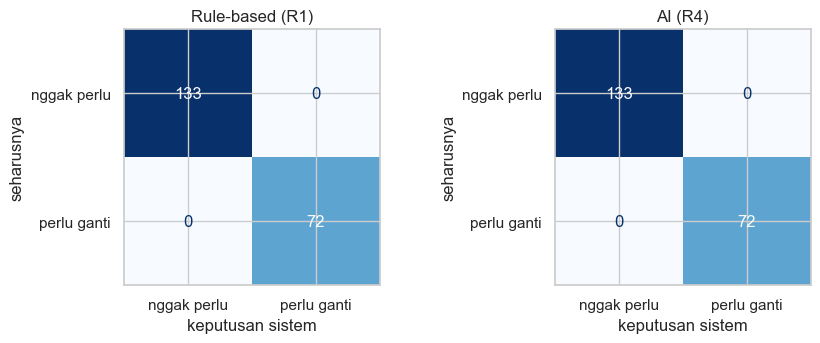

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, col) in zip(axes, [("Rule-based (R1)", "rule_based"), ("AI (R4)", "ai")]):
    cm = confusion_matrix(cmp["truth"], cmp[col], labels=[False, True])
    ConfusionMatrixDisplay(cm, display_labels=["nggak perlu", "perlu ganti"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("keputusan sistem")
    ax.set_ylabel("seharusnya")
fig.tight_layout()
fig.savefig("results/ai_vs_rule_based_cm.png", dpi=150)
plt.show()

Di data test normal, kedua rules hasilny sama persis. Jadi kalau sensornya stabil, maka kedua rules sama bagusnya

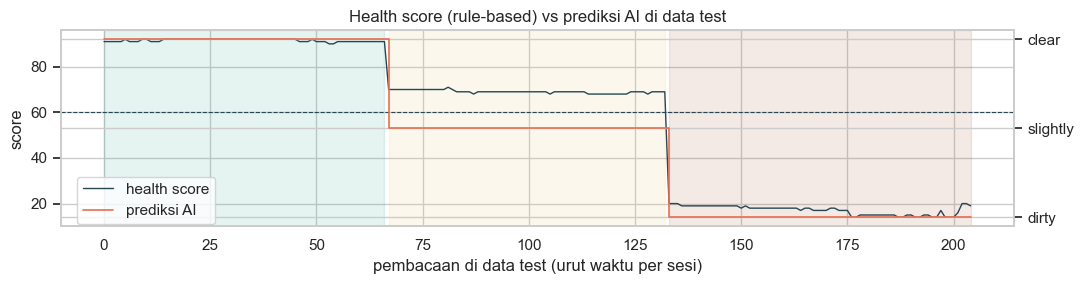

In [29]:
fig, ax = plt.subplots(figsize=(11, 3))
x = np.arange(len(cmp))
ax.plot(x, cmp["score"], color="#264653", lw=1, label="health score")
ax.axhline(SCORE_THRESHOLD, color="#264653", ls="--", lw=0.8)
ax2 = ax.twinx()
level = cmp["ml"].map({"dirty": 0, "slightly_turbid": 1, "clear": 2})  # dibalik biar searah sama score
ax2.step(x, level, color="#e76f51", lw=1.2, where="post", label="prediksi AI")
ax2.set_yticks([0, 1, 2], ["dirty", "slightly", "clear"])
for label in LABELS:
    idx = np.where(cmp["label"] == label)[0]
    ax.axvspan(idx.min(), idx.max(), color=COLORS[label], alpha=0.12)
ax.set_xlabel("pembacaan di data test (urut waktu per sesi)")
ax.set_ylabel("score")
ax.set_title("Health score (rule-based) vs prediksi AI di data test")
fig.legend(loc="lower left", bbox_to_anchor=(0.07, 0.2))
fig.tight_layout()
fig.savefig("results/ai_vs_rule_based_timeline.png", dpi=150)
plt.show()


Grafik ini nunjukkin health score vs prediction AI di test set over time

Sensor turbidity gampang berubah walaupun airnya sama, karena gelembung atau airnya teraduk atau bahkan tgangannya turun padahal airnya ga berubah, tapi karena health scorenya dibwh 50 jadi rule based bakal kira airnya kotor dan nyalakan pompanya. Disini kita test kerjain itu dengan cara data test diturunin pelan2 dan health scorenya dihitung ulang. Saya bakal itung berapa banyak alrm palsu dari sistem padahal labelnya harusnya bukan dirty

In [30]:
TURB_V_CLEAR, TURB_V_SPAN = 1.75, 0.55
shift_rows = []
for shift in [0, -0.25, -0.5, -0.75]:
    noisy = cmp.copy()
    noisy["turb_v"] = noisy["turb_v"] + shift
    noisy["turb"] = np.clip((TURB_V_CLEAR - noisy["turb_v"]) / TURB_V_SPAN * 100, 0, 100)
    noisy["score"] = noisy.apply(health_score, axis=1)
    noisy["ml"], noisy["ml_conf"] = esp32_vote(esp_model, noisy[FEATURES].values)
    rule = noisy["score"] < SCORE_THRESHOLD
    ai = (noisy["ml"] == "dirty") & (noisy["ml_conf"] >= ML_MIN_CONFIDENCE)
    for name, flags in [("Rule-based (R1)", rule), ("AI (R4)", ai)]:
        not_dirty = ~noisy["truth"]
        shift_rows.append({
            "geser turb_v (V)": shift, "sistem": name,
            "alarm palsu clear": int((flags & (noisy["label"] == "clear")).sum()),
            "alarm palsu slightly": int((flags & (noisy["label"] == "slightly_turbid")).sum()),
            "alarm palsu (%)": round(100 * (flags & not_dirty).sum() / not_dirty.sum(), 1),
            "recall dirty": recall_score(noisy["truth"], flags, zero_division=0),
        })
shift_df = pd.DataFrame(shift_rows)
shift_df.to_csv("results/turbidity_shift_test.csv", index=False)
shift_df

,geser turb_v (V),sistem,alarm palsu clear,alarm palsu slightly,alarm palsu (%),recall dirty
0,0.00,Rule-based (R1),0,0,0.0,1.0
1,0.00,AI (R4),0,0,0.0,1.0
2,-0.25,Rule-based (R1),0,66,49.6,1.0
3,-0.25,AI (R4),0,0,0.0,1.0
4,-0.50,Rule-based (R1),67,66,100.0,1.0
5,-0.50,AI (R4),0,0,0.0,1.0
6,-0.75,Rule-based (R1),67,66,100.0,1.0
7,-0.75,AI (R4),0,0,0.0,1.0


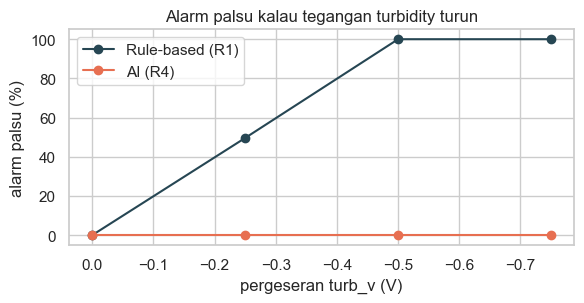

In [31]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for name, color in [("Rule-based (R1)", "#264653"), ("AI (R4)", "#e76f51")]:
    part = shift_df[shift_df["sistem"] == name]
    ax.plot(part["geser turb_v (V)"], part["alarm palsu (%)"], marker="o", color=color, label=name)
ax.set_xlabel("pergeseran turb_v (V)")
ax.set_ylabel("alarm palsu (%)")
ax.set_title("Alarm palsu kalau tegangan turbidity turun")
ax.invert_xaxis()
ax.legend()
fig.tight_layout()
fig.savefig("results/turbidity_shift_test.png", dpi=150)
plt.show()

Dari table dan grafik itu kita bisa lihat, turun 0.25 V aja rule based udh kasih false alarm dimana pembacaannya harusnya slightly turbid dan setelah -0.5 air clear juga dianggap kotor, sedangan AI ttp di 0% karena keputusannya mostly dari TDS ga ikut berubah. Jadi AI lebih tahan terhadap sensor turbidity yg naik turun


## Kesimpulan

Kesimpulannya projek ini nunjukkin bahwa TDS itu fitu paling dominan disini. Sedangkan suhu sama sekali tidak dipakai karna hanaya kasih tau suhu ruangan. Untuk implementasi model ini ke ESP, model random forest yang dikecilin berhasil di convert ke C++ pakaimicroml gen dan ditanamin ke ESP32. Lalu, secara perofrma AI terbukti lebih tahan gangguan sensor dariapda sistem rule based dimana sistem rule based memebrikan 100% false alarm, tapi AI ttp stabil di 0%.